# Gecikme riskini hangi bilgiyle tahmin ederiz?

Depo, sipariş açıldığı anda gecikme riskini tahmin etmek istiyor. Ürün adedi, mevcut kuyruk ve söz verilen süre biliniyor; teslim sonrası toplam süre henüz bilinmiyor. İki senaryo aynı işte doğru veri erişimi ile sızıntılı erişimi karşılaştırıyor. Yüksek skorun kullanılabilir bilgiyle kazanılıp kazanılmadığı kritik.

**Karar:** Model, taban oranından daha yararlı olasılık ve operasyonun kaldırabileceği hata yükü üretiyor mu?

**Birim:** Sipariş; amaç aynı depoda gelecekteki sipariş riskidir. Gün sınırları eğitim/seçim/testi ayırır.

**Yöntem:** Önce bilgi anını tanımla. Lojistik/orman ailesini sadece validasyon Brier ile seç; eşiği aynı seçim döneminde önceden tanımlanmış hata maliyetiyle belirle. Aile/eşik sabitken geçmişi yeniden eğit ve son dönemi bir kez raporla.

Veriler sabit tohumla üretilmiş sentetiktir; gerçek şirket veya kişi verisi değildir. Python paket sürümleri ZIP içindeki requirements.txt dosyasındadır. Her senaryo kendi verisini üretir; CSV dosyaları hazır örneklerle birlikte verilir.


## Senaryo: Tahmin anında bilinen özellikler

Önce beklediğin sonucu yaz. Aşağıdaki hücre analizin tamamını içerir; seçilmiş senaryoyu değiştirip yeniden çalıştırabilirsin.


                    Ölçü                            Değer
Eğitim / seçim / final n                  784 / 196 / 196
          Seçilmiş model                         Lojistik
       Sabit karar eşiği                              0.1
             Final Brier                         0.102144
           Final ROC-AUC                         0.752982
                Final AP                         0.295934
  Kaçırma / yanlış alarm                           2 / 95
         Özellik erişimi Tahmin anında bilinen özellikler

Aile seçimi yalnız validasyon Brier ile
   model  validation_Brier  validation_AP
Lojistik          0.115516       0.240320
   Orman          0.115657       0.243194

Final testte taban karşılaştırması
             model  test_Brier  test_ROC_AUC  test_AP
Sabit eğitim oranı    0.111479      0.500000 0.127551
     Seçilen model    0.102144      0.752982 0.295934

Karar: Lojistik modeli ve 0.10 eşik seçim döneminden geldi. Final testte Brier=0.1021; 1.000 siparişte maliyet=5

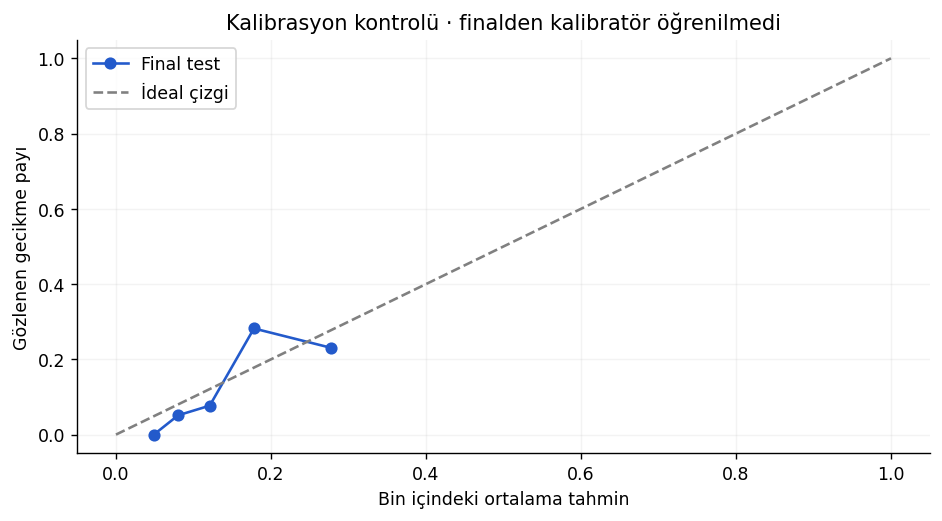

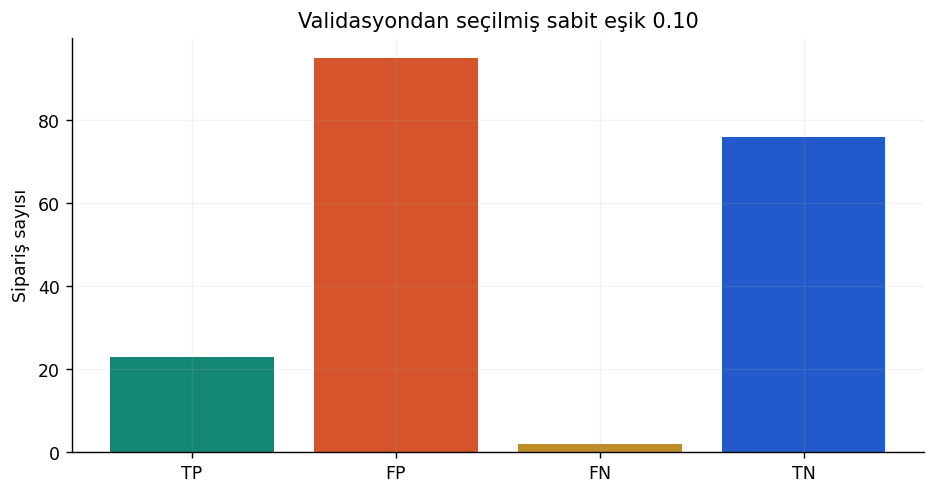

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats, special
import statsmodels.api as sm
import statsmodels.formula.api as smf
from statsmodels.stats.contingency_tables import mcnemar
from statsmodels.stats.multicomp import pairwise_tukeyhsd
from statsmodels.stats.oneway import anova_oneway
from statsmodels.stats.diagnostic import acorr_ljungbox
from statsmodels.tsa.statespace.sarimax import SARIMAX
plt.rcParams.update({'figure.figsize':(8.8,4.3),'axes.spines.top':False,'axes.spines.right':False,'axes.grid':True,'grid.alpha':.15})

def tbl(df,title):return {'title':title,'columns':[str(c) for c in df.columns],'rows':df.where(pd.notnull(df),None).values.tolist()}

def classifier(scenario='default'):
 from sklearn.pipeline import make_pipeline
 from sklearn.preprocessing import StandardScaler
 from sklearn.linear_model import LogisticRegression
 from sklearn.ensemble import RandomForestClassifier
 from sklearn.metrics import brier_score_loss,roc_auc_score,average_precision_score,log_loss
 from sklearn.calibration import calibration_curve
 rng=np.random.default_rng(260807);day=np.repeat(np.arange(1,85),14);N=len(day);items=rng.poisson(6,N)+1;queue=np.maximum(1,rng.normal(35+.2*day,15));promise=rng.choice([24,48,72],N);night=rng.binomial(1,.3,N);p=special.expit(-3.3+.08*items+.035*queue-.025*promise+.45*night+.7*(items>10)*(queue>60));y=rng.binomial(1,p);final_duration=promise+np.where(y==1,rng.gamma(2,4,N),-rng.uniform(.5,10,N));raw=pd.DataFrame({'order_id':np.arange(1,N+1),'day':day,'items':items,'queue_at_open':queue,'promise_hours':promise,'night':night,'actual_late':y,'final_duration_hours':final_duration});features=['items','queue_at_open','promise_hours','night']+(['final_duration_hours']if scenario=='leaky'else[]);tr=day<=56;va=(day>56)&(day<=70);te=day>70;models=[('Lojistik',make_pipeline(StandardScaler(),LogisticRegression(C=1,max_iter=1000,random_state=7))),('Orman',RandomForestClassifier(n_estimators=80,max_depth=5,min_samples_leaf=8,random_state=7,n_jobs=1))];rows=[]
 for name,m in models:
  m.fit(raw.loc[tr,features],y[tr]);pv=m.predict_proba(raw.loc[va,features])[:,1];rows.append([name,brier_score_loss(y[va],pv),average_precision_score(y[va],pv)])
 selected=int(np.argmin([r[1]for r in rows]));name,model=models[selected];pv=model.predict_proba(raw.loc[va,features])[:,1];thresholds=np.arange(.1,.91,.05);cost=lambda actual,pred:float(np.mean((pred==1)&(actual==0))+10*np.mean((pred==0)&(actual==1)));costs=[cost(y[va],pv>=t)for t in thresholds];threshold=float(thresholds[np.argmin(costs)]);model.fit(raw.loc[~te,features],y[~te]);pt=model.predict_proba(raw.loc[te,features])[:,1];decision=pt>=threshold;actual=y[te];TP=int(np.sum(decision&(actual==1)));FP=int(np.sum(decision&(actual==0)));FN=int(np.sum(~decision&(actual==1)));TN=int(np.sum(~decision&(actual==0)));baseline=np.full(np.sum(te),y[tr].mean());validation=pd.DataFrame(rows,columns=['model','validation_Brier','validation_AP']);scores=pd.DataFrame([['Sabit eğitim oranı',brier_score_loss(actual,baseline),roc_auc_score(actual,baseline),average_precision_score(actual,baseline)],['Seçilen model',brier_score_loss(actual,pt),roc_auc_score(actual,pt),average_precision_score(actual,pt)]],columns=['model','test_Brier','test_ROC_AUC','test_AP']);raw['partition']=np.where(tr,'train',np.where(va,'validation','final_test'));prediction=raw.loc[te,['order_id','actual_late']].copy();prediction['score']=pt;prediction['decision']=decision.astype(int)
 fig,ax=plt.subplots();obs,mean=calibration_curve(actual,pt,n_bins=5,strategy='quantile');ax.plot(mean,obs,'o-',color='#235ACB',label='Final test');ax.plot([0,1],[0,1],'--',color='gray',label='İdeal çizgi');ax.set(xlabel='Bin içindeki ortalama tahmin',ylabel='Gözlenen gecikme payı',title='Kalibrasyon kontrolü · finalden kalibratör öğrenilmedi');ax.legend()
 fig2,ax2=plt.subplots();ax2.bar(['TP','FP','FN','TN'],[TP,FP,FN,TN],color=['#148774','#D5542B','#BE8D28','#235ACB']);ax2.set(ylabel='Sipariş sayısı',title=f'Validasyondan seçilmiş sabit eşik {threshold:.2f}')
 result_text=('Bu senaryoda final süre özelliği teslimden sonra oluşuyor. Skor yüksek olsa bile tahmin anında kullanılamaz; devreye alma önerisi olarak sunulamaz.'if scenario=='leaky'else f'{name} modeli ve {threshold:.2f} eşik seçim döneminden geldi. Final testte Brier={brier_score_loss(actual,pt):.4f}; 1.000 siparişte maliyet={1000*cost(actual,decision):.1f} puan. Operasyon kapasitesi ve yeni dönem izleme planı olmadan otomatik devreye alma kararı verme.')
 assert raw.loc[tr,'day'].max()<raw.loc[va,'day'].min()and raw.loc[va,'day'].max()<raw.loc[te,'day'].min();assert set(np.unique(actual))=={0,1}
 return dict(metrics={'Eğitim / seçim / final n':f'{tr.sum()} / {va.sum()} / {te.sum()}','Seçilmiş model':name,'Sabit karar eşiği':threshold,'Final Brier':brier_score_loss(actual,pt),'Final ROC-AUC':roc_auc_score(actual,pt),'Final AP':average_precision_score(actual,pt),'Kaçırma / yanlış alarm':f'{FN} / {FP}','Özellik erişimi':'Uygun değil: teslim sonrası bilgi'if scenario=='leaky'else'Tahmin anında bilinen özellikler'},tables=[tbl(validation,'Aile seçimi yalnız validasyon Brier ile'),tbl(scores,'Final testte taban karşılaştırması')],figures=[('Kalibrasyon grafiği bin ortalamalarıdır; küçük test örneklemindeki oynaklığı unutma.',fig),('Doğruluk yanında iki hata türünü ve maliyetini ayrı göster.',fig2)],frames={'siparis_model_verisi':raw,'bagimsiz_final_sonuclari':prediction},steps=['Gün 1–56 eğitim, 57–70 seçim, 71–84 final test. Özelliğin sipariş açılırken bilinip bilinmediğini denetle.','Ölçekleyici lojistik pipeline içinde yalnız eğitimde öğrenilir. İki önceden seçilmiş adayın ailesi validasyon Brier ile seçilir.','Eşik yalnız validasyonda FP maliyeti 1, FN maliyeti 10 ile seçilir. Aile/eşik sabitken model ilk 70 günde yeniden eğitilip finalde bir kez değerlendirilir.','Brier, ROC-AUC, AP, kalibrasyon ve karar tablosu farklı sorulara cevap verir. Sızıntı senaryosundaki iyi skoru kullanım kanıtı sayma.'],decision=result_text,diagnostics={'n_train':int(tr.sum()),'n_val':int(va.sum()),'n_test':int(te.sum()),'train_max_day':int(day[tr].max()),'val_min_day':int(day[va].min()),'val_max_day':int(day[va].max()),'test_min_day':int(day[te].min()),'features':features,'selected':name,'threshold':threshold,'brier':brier_score_loss(actual,pt),'auc':roc_auc_score(actual,pt),'AP':average_precision_score(actual,pt),'TP':TP,'FP':FP,'FN':FN,'TN':TN,'leaky':scenario=='leaky'},limit='Sentetik, tek depo, günlük sıralı siparişler; hedef gelecekteki aynı kullanım ortamıdır. Yeni müşteri/çok depo genellemesi ayrıca test ister. Hata maliyetleri öğretim varsayımıdır. Kalibrasyon yalnız incelenir; ayrı kalibratör eğitilmez. Senaryo karşılaştırmaları final testte yeni seçim yapmak için kullanılmaz.')

result=classifier('default')
print(pd.DataFrame(list(result['metrics'].items()),columns=['Olcu','Deger']).to_string(index=False))
for t in result['tables']: print(t['title']); print(pd.DataFrame(t['rows'],columns=t['columns']).to_string(index=False))
print('Karar:', result['decision']); print('Sinir:',result['limit'])
for caption,fig in result['figures']: print(caption); plt.show()


## Senaryo: Sızıntılı teslim sonrası süre ekleniyor

Önce beklediğin sonucu yaz. Aşağıdaki hücre analizin tamamını içerir; seçilmiş senaryoyu değiştirip yeniden çalıştırabilirsin.


                    Ölçü                             Değer
Eğitim / seçim / final n                   784 / 196 / 196
          Seçilmiş model                          Lojistik
       Sabit karar eşiği                              0.25
             Final Brier                          0.020087
           Final ROC-AUC                               1.0
                Final AP                               1.0
  Kaçırma / yanlış alarm                             0 / 1
         Özellik erişimi Uygun değil: teslim sonrası bilgi

Aile seçimi yalnız validasyon Brier ile
   model  validation_Brier  validation_AP
Lojistik          0.023972            1.0
   Orman          0.041642            1.0

Final testte taban karşılaştırması
             model  test_Brier  test_ROC_AUC  test_AP
Sabit eğitim oranı    0.111479           0.5 0.127551
     Seçilen model    0.020087           1.0 1.000000

Karar: Bu senaryoda final süre özelliği teslimden sonra oluşuyor. Skor yüksek olsa bile tahmin anında k

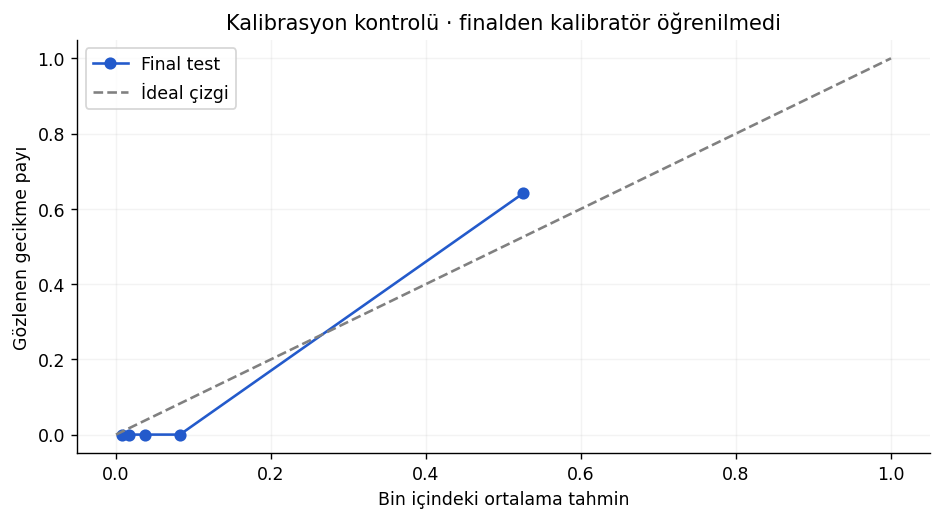

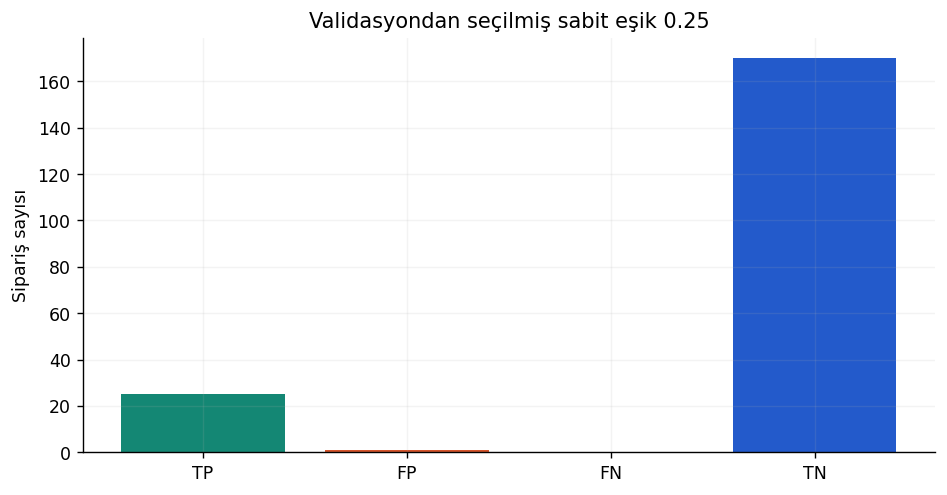

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats, special
import statsmodels.api as sm
import statsmodels.formula.api as smf
from statsmodels.stats.contingency_tables import mcnemar
from statsmodels.stats.multicomp import pairwise_tukeyhsd
from statsmodels.stats.oneway import anova_oneway
from statsmodels.stats.diagnostic import acorr_ljungbox
from statsmodels.tsa.statespace.sarimax import SARIMAX
plt.rcParams.update({'figure.figsize':(8.8,4.3),'axes.spines.top':False,'axes.spines.right':False,'axes.grid':True,'grid.alpha':.15})

def tbl(df,title):return {'title':title,'columns':[str(c) for c in df.columns],'rows':df.where(pd.notnull(df),None).values.tolist()}

def classifier(scenario='default'):
 from sklearn.pipeline import make_pipeline
 from sklearn.preprocessing import StandardScaler
 from sklearn.linear_model import LogisticRegression
 from sklearn.ensemble import RandomForestClassifier
 from sklearn.metrics import brier_score_loss,roc_auc_score,average_precision_score,log_loss
 from sklearn.calibration import calibration_curve
 rng=np.random.default_rng(260807);day=np.repeat(np.arange(1,85),14);N=len(day);items=rng.poisson(6,N)+1;queue=np.maximum(1,rng.normal(35+.2*day,15));promise=rng.choice([24,48,72],N);night=rng.binomial(1,.3,N);p=special.expit(-3.3+.08*items+.035*queue-.025*promise+.45*night+.7*(items>10)*(queue>60));y=rng.binomial(1,p);final_duration=promise+np.where(y==1,rng.gamma(2,4,N),-rng.uniform(.5,10,N));raw=pd.DataFrame({'order_id':np.arange(1,N+1),'day':day,'items':items,'queue_at_open':queue,'promise_hours':promise,'night':night,'actual_late':y,'final_duration_hours':final_duration});features=['items','queue_at_open','promise_hours','night']+(['final_duration_hours']if scenario=='leaky'else[]);tr=day<=56;va=(day>56)&(day<=70);te=day>70;models=[('Lojistik',make_pipeline(StandardScaler(),LogisticRegression(C=1,max_iter=1000,random_state=7))),('Orman',RandomForestClassifier(n_estimators=80,max_depth=5,min_samples_leaf=8,random_state=7,n_jobs=1))];rows=[]
 for name,m in models:
  m.fit(raw.loc[tr,features],y[tr]);pv=m.predict_proba(raw.loc[va,features])[:,1];rows.append([name,brier_score_loss(y[va],pv),average_precision_score(y[va],pv)])
 selected=int(np.argmin([r[1]for r in rows]));name,model=models[selected];pv=model.predict_proba(raw.loc[va,features])[:,1];thresholds=np.arange(.1,.91,.05);cost=lambda actual,pred:float(np.mean((pred==1)&(actual==0))+10*np.mean((pred==0)&(actual==1)));costs=[cost(y[va],pv>=t)for t in thresholds];threshold=float(thresholds[np.argmin(costs)]);model.fit(raw.loc[~te,features],y[~te]);pt=model.predict_proba(raw.loc[te,features])[:,1];decision=pt>=threshold;actual=y[te];TP=int(np.sum(decision&(actual==1)));FP=int(np.sum(decision&(actual==0)));FN=int(np.sum(~decision&(actual==1)));TN=int(np.sum(~decision&(actual==0)));baseline=np.full(np.sum(te),y[tr].mean());validation=pd.DataFrame(rows,columns=['model','validation_Brier','validation_AP']);scores=pd.DataFrame([['Sabit eğitim oranı',brier_score_loss(actual,baseline),roc_auc_score(actual,baseline),average_precision_score(actual,baseline)],['Seçilen model',brier_score_loss(actual,pt),roc_auc_score(actual,pt),average_precision_score(actual,pt)]],columns=['model','test_Brier','test_ROC_AUC','test_AP']);raw['partition']=np.where(tr,'train',np.where(va,'validation','final_test'));prediction=raw.loc[te,['order_id','actual_late']].copy();prediction['score']=pt;prediction['decision']=decision.astype(int)
 fig,ax=plt.subplots();obs,mean=calibration_curve(actual,pt,n_bins=5,strategy='quantile');ax.plot(mean,obs,'o-',color='#235ACB',label='Final test');ax.plot([0,1],[0,1],'--',color='gray',label='İdeal çizgi');ax.set(xlabel='Bin içindeki ortalama tahmin',ylabel='Gözlenen gecikme payı',title='Kalibrasyon kontrolü · finalden kalibratör öğrenilmedi');ax.legend()
 fig2,ax2=plt.subplots();ax2.bar(['TP','FP','FN','TN'],[TP,FP,FN,TN],color=['#148774','#D5542B','#BE8D28','#235ACB']);ax2.set(ylabel='Sipariş sayısı',title=f'Validasyondan seçilmiş sabit eşik {threshold:.2f}')
 result_text=('Bu senaryoda final süre özelliği teslimden sonra oluşuyor. Skor yüksek olsa bile tahmin anında kullanılamaz; devreye alma önerisi olarak sunulamaz.'if scenario=='leaky'else f'{name} modeli ve {threshold:.2f} eşik seçim döneminden geldi. Final testte Brier={brier_score_loss(actual,pt):.4f}; 1.000 siparişte maliyet={1000*cost(actual,decision):.1f} puan. Operasyon kapasitesi ve yeni dönem izleme planı olmadan otomatik devreye alma kararı verme.')
 assert raw.loc[tr,'day'].max()<raw.loc[va,'day'].min()and raw.loc[va,'day'].max()<raw.loc[te,'day'].min();assert set(np.unique(actual))=={0,1}
 return dict(metrics={'Eğitim / seçim / final n':f'{tr.sum()} / {va.sum()} / {te.sum()}','Seçilmiş model':name,'Sabit karar eşiği':threshold,'Final Brier':brier_score_loss(actual,pt),'Final ROC-AUC':roc_auc_score(actual,pt),'Final AP':average_precision_score(actual,pt),'Kaçırma / yanlış alarm':f'{FN} / {FP}','Özellik erişimi':'Uygun değil: teslim sonrası bilgi'if scenario=='leaky'else'Tahmin anında bilinen özellikler'},tables=[tbl(validation,'Aile seçimi yalnız validasyon Brier ile'),tbl(scores,'Final testte taban karşılaştırması')],figures=[('Kalibrasyon grafiği bin ortalamalarıdır; küçük test örneklemindeki oynaklığı unutma.',fig),('Doğruluk yanında iki hata türünü ve maliyetini ayrı göster.',fig2)],frames={'siparis_model_verisi':raw,'bagimsiz_final_sonuclari':prediction},steps=['Gün 1–56 eğitim, 57–70 seçim, 71–84 final test. Özelliğin sipariş açılırken bilinip bilinmediğini denetle.','Ölçekleyici lojistik pipeline içinde yalnız eğitimde öğrenilir. İki önceden seçilmiş adayın ailesi validasyon Brier ile seçilir.','Eşik yalnız validasyonda FP maliyeti 1, FN maliyeti 10 ile seçilir. Aile/eşik sabitken model ilk 70 günde yeniden eğitilip finalde bir kez değerlendirilir.','Brier, ROC-AUC, AP, kalibrasyon ve karar tablosu farklı sorulara cevap verir. Sızıntı senaryosundaki iyi skoru kullanım kanıtı sayma.'],decision=result_text,diagnostics={'n_train':int(tr.sum()),'n_val':int(va.sum()),'n_test':int(te.sum()),'train_max_day':int(day[tr].max()),'val_min_day':int(day[va].min()),'val_max_day':int(day[va].max()),'test_min_day':int(day[te].min()),'features':features,'selected':name,'threshold':threshold,'brier':brier_score_loss(actual,pt),'auc':roc_auc_score(actual,pt),'AP':average_precision_score(actual,pt),'TP':TP,'FP':FP,'FN':FN,'TN':TN,'leaky':scenario=='leaky'},limit='Sentetik, tek depo, günlük sıralı siparişler; hedef gelecekteki aynı kullanım ortamıdır. Yeni müşteri/çok depo genellemesi ayrıca test ister. Hata maliyetleri öğretim varsayımıdır. Kalibrasyon yalnız incelenir; ayrı kalibratör eğitilmez. Senaryo karşılaştırmaları final testte yeni seçim yapmak için kullanılmaz.')

result=classifier('leaky')
print(pd.DataFrame(list(result['metrics'].items()),columns=['Olcu','Deger']).to_string(index=False))
for t in result['tables']: print(t['title']); print(pd.DataFrame(t['rows'],columns=t['columns']).to_string(index=False))
print('Karar:', result['decision']); print('Sinir:',result['limit'])
for caption,fig in result['figures']: print(caption); plt.show()


## Uygula ve karar notu

Sızıntı senaryosunun skoru daha iyi görünse bile neden kullanılamadığını zaman çizgisiyle açıkla. Final testin hangi kararlar için kullanıldığını kontrol et.

Kabul ölçütleri: analiz birimini doğru tanımla; yöntem seçimini gerekçelendir; etkiyi/aralığı doğal birimle raporla; varsayımı ve bir sonraki veri ihtiyacını yaz.
